# 2. Análisis exploratorio (EDA)

Todo lo univariado se calcula sobre el **conjunto completo** con Polars en modo perezoso. Las
medidas de asociación, que requieren matrices, se calculan sobre una muestra de entrenamiento.
Ningún resultado de este capítulo se usa para ajustar el modelo con datos de prueba: el PSI
solo **describe** la deriva entre entrenamiento y prueba.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src") if Path.cwd().name == "notebooks" else str(Path.cwd() / "src"))
import numpy as np, pandas as pd, polars as pl
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.feature_selection import mutual_info_classif
from ctr.nbutils import setup, savefig, show, SERIES, MUTED, SEQ_CMAP, DIV_CMAP, INK2
from ctr import data
from ctr.features import CTRFeaturizer

cfg, RES, FIG = setup()
lf = data.scan(cfg.path("parquet_dir"))
SP = cfg["split"]
lf_train = lf.filter(pl.col("day").is_in(SP["train_days"]))
lf_test = lf.filter(pl.col("day") == SP["test_day"])
COLS = cfg.feature_cols

Perfil: colab  |  resultados en: /content/deep-learning-01-ctr-mlp/results


## 2.1 Tipos y valores faltantes

In [2]:
schema = lf.collect_schema()
nulls = lf.select([pl.col(c).null_count().alias(c) for c in schema.names()]).collect(engine="streaming")
tipos = pd.DataFrame({"variable": schema.names(), "tipo": [str(t) for t in schema.dtypes()],
                      "nulos": nulls.row(0)})
show(tipos, 40)

,variable,tipo,nulos
0,id,String,0
1,click,Int8,0
2,hour,Int32,0
3,C1,String,0
4,banner_pos,String,0
5,site_id,String,0
6,site_domain,String,0
7,site_category,String,0
8,app_id,String,0
9,app_domain,String,0


## 2.2 Variable objetivo: distribución y tasa base por día, hora, día de la semana y franja

Tasa base global: 0.1698  (desbalance 4.9:1)


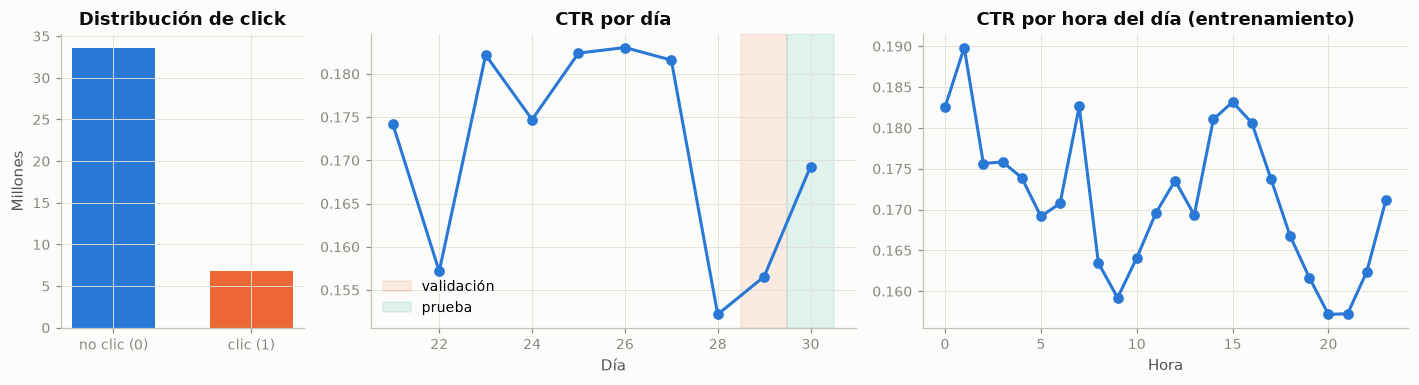

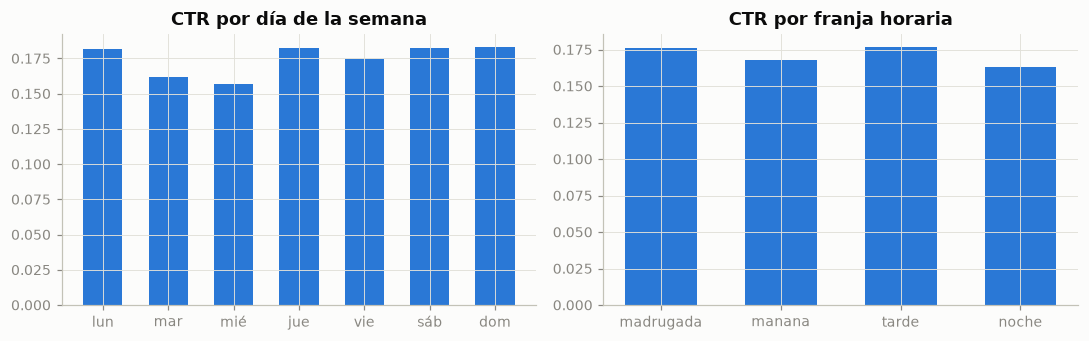

In [3]:
clicks = lf.group_by("click").len().sort("click").collect().to_pandas()
by_day = lf.group_by("day").agg(pl.col("click").mean().alias("ctr"), pl.len().alias("n")).sort("day").collect().to_pandas()
by_hour = lf_train.group_by(pl.col("hour_of_day").cast(pl.Int32)).agg(pl.col("click").mean().alias("ctr"), pl.len().alias("n")).sort("hour_of_day").collect().to_pandas()
by_dow = lf_train.group_by(pl.col("dow").cast(pl.Int32)).agg(pl.col("click").mean().alias("ctr"), pl.len().alias("n")).sort("dow").collect().to_pandas()
by_fr = lf_train.group_by("franja").agg(pl.col("click").mean().alias("ctr"), pl.len().alias("n")).collect().to_pandas()
by_fr = by_fr.set_index("franja").loc[[f for f in ["madrugada", "manana", "tarde", "noche"] if f in set(by_fr["franja"])]].reset_index()
base = clicks.set_index("click")["len"]
print(f"Tasa base global: {base.get(1, 0) / base.sum():.4f}  (desbalance {base.get(0,0)/max(base.get(1,1),1):.1f}:1)")

fig, axs = plt.subplots(1, 3, figsize=(13, 3.6), gridspec_kw={"width_ratios": [1, 2, 2]})
axs[0].bar(["no clic (0)", "clic (1)"], clicks["len"] / 1e6, color=[SERIES[0], SERIES[1]], width=0.6)
axs[0].set_title("Distribución de click"); axs[0].set_ylabel("Millones")
axs[1].plot(by_day["day"], by_day["ctr"], marker="o", color=SERIES[0])
axs[1].axvspan(SP["valid_day"] - 0.5, SP["valid_day"] + 0.5, color=SERIES[1], alpha=0.12, label="validación")
axs[1].axvspan(SP["test_day"] - 0.5, SP["test_day"] + 0.5, color=SERIES[2], alpha=0.12, label="prueba")
axs[1].set_title("CTR por día"); axs[1].set_xlabel("Día"); axs[1].legend()
axs[2].plot(by_hour["hour_of_day"], by_hour["ctr"], marker="o", color=SERIES[0])
axs[2].set_title("CTR por hora del día (entrenamiento)"); axs[2].set_xlabel("Hora")
savefig(fig, FIG, "02_click_ctr_dia_hora")

fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
dias = ["lun", "mar", "mié", "jue", "vie", "sáb", "dom"]
axs[0].bar([dias[i] for i in by_dow["dow"]], by_dow["ctr"], color=SERIES[0], width=0.6)
axs[0].set_title("CTR por día de la semana")
axs[1].bar(by_fr["franja"], by_fr["ctr"], color=SERIES[0], width=0.6)
axs[1].set_title("CTR por franja horaria")
savefig(fig, FIG, "02_ctr_dow_franja")

## 2.3 Cardinalidad y cola larga

Para cada variable: número de categorías en entrenamiento, proporción de categorías vistas una
sola vez, y cobertura que logran las categorías que superan el umbral de raras. La curva de cola
larga muestra qué fracción de las impresiones cubren las *k* categorías más frecuentes.

,variable,categorias,pct_vistas_una_vez,categorias_>=20,cobertura_>=20_pct
5,device_ip,5566572,49.89,174819,55.68
4,device_id,2217500,63.15,25003,86.00
2,app_id,8095,19.85,2877,99.92
6,device_model,8036,9.83,5096,99.95
1,site_domain,7299,24.77,2662,99.94
0,site_id,4551,11.47,2593,99.97
7,C14,2252,1.95,1962,99.99
3,app_domain,539,25.05,188,100.00
8,C17,372,0.54,361,100.00
10,C20,172,0.58,165,100.00


/content/deep-learning-01-ctr-mlp/src/ctr/nbutils.py:56: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()


/content/deep-learning-01-ctr-mlp/src/ctr/nbutils.py:57: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.savefig(Path(figdir) / f"{name}.png", bbox_inches="tight")


/usr/local/lib/python3.13/dist-packages/IPython/core/events.py:89: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


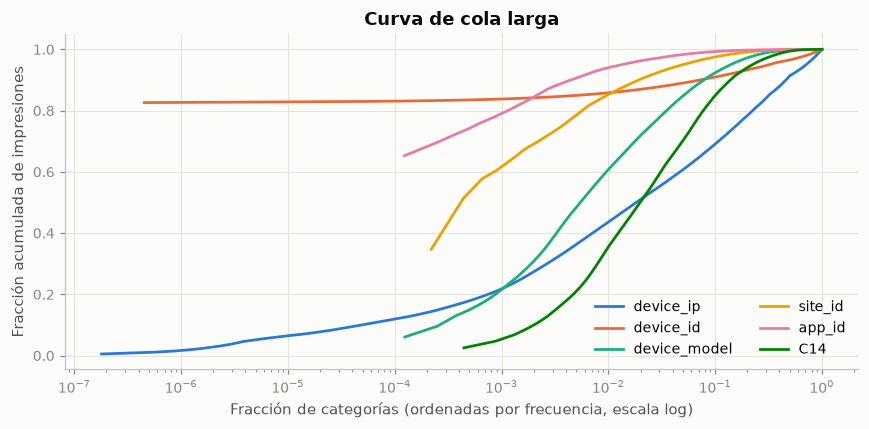

In [4]:
m = cfg["rare_min_count"]
card_rows, tails = [], {}
for c in COLS:
    vc = lf_train.group_by(c).len().collect(engine="streaming")
    cnt = np.sort(vc["len"].to_numpy())[::-1]
    tot = cnt.sum()
    card_rows.append({"variable": c, "categorias": len(cnt), "pct_vistas_una_vez": (cnt == 1).mean() * 100,
                      f"categorias_>={m}": int((cnt >= m).sum()),
                      f"cobertura_>={m}_pct": cnt[cnt >= m].sum() / tot * 100})
    tails[c] = np.cumsum(cnt) / tot
card = pd.DataFrame(card_rows).sort_values("categorias", ascending=False)
card.to_csv(RES / "eda_cardinalidad.csv", index=False)
show(card, 30, "{:.2f}")

fig, ax = plt.subplots(figsize=(8, 4))
for i, c in enumerate(["device_ip", "device_id", "device_model", "site_id", "app_id", "C14"]):
    y = tails[c]
    x = np.arange(1, len(y) + 1) / len(y)
    ax.plot(x, y, label=c, color=SERIES[i], linewidth=1.8)
ax.set_xscale("log"); ax.set_xlabel("Fracción de categorías (ordenadas por frecuencia, escala log)")
ax.set_ylabel("Fracción acumulada de impresiones"); ax.set_title("Curva de cola larga")
ax.legend(ncols=2)
savefig(fig, FIG, "02_cola_larga")

## 2.4 Frecuencias de las principales categóricas y su CTR

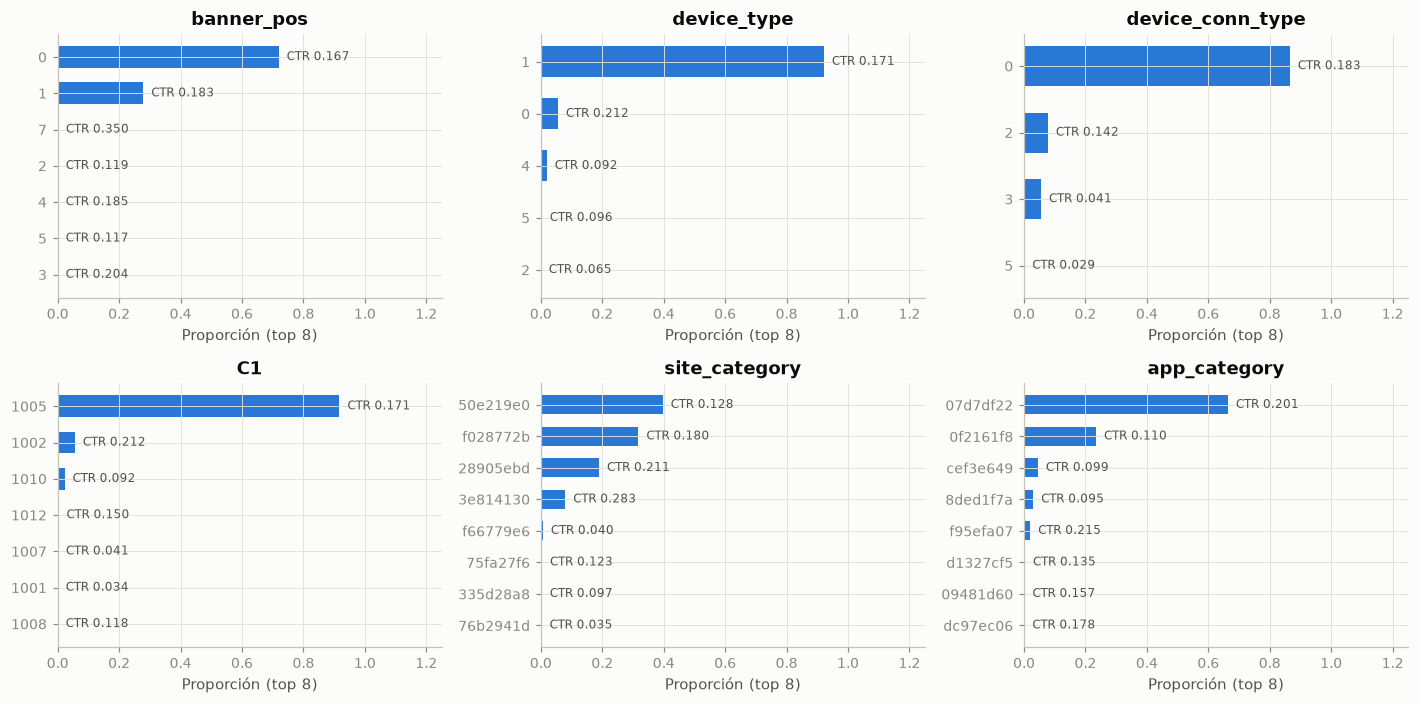

In [5]:
top_cols = ["banner_pos", "device_type", "device_conn_type", "C1", "site_category", "app_category"]
fig, axs = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, c in zip(axs.ravel(), top_cols):
    t = (lf_train.group_by(c).agg(pl.len().alias("n"), pl.col("click").mean().alias("ctr"))
         .sort("n", descending=True).head(8).collect().to_pandas())
    ax.barh(t[c].astype(str)[::-1], t["n"][::-1] / t["n"].sum(), color=SERIES[0], height=0.6)
    for yy, (n_, ctr_) in enumerate(zip(t["n"][::-1], t["ctr"][::-1])):
        ax.text(n_ / t["n"].sum(), yy, f"  CTR {ctr_:.3f}", va="center", fontsize=8, color=INK2)
    ax.set_title(c); ax.set_xlabel("Proporción (top 8)")
    ax.set_xlim(0, 1.25)
savefig(fig, FIG, "02_top_categorias")

## 2.5 Numéricas derivadas

Avazu no trae variables numéricas propiamente dichas. Las numéricas del modelo son derivadas:
la hora y el **log de la frecuencia** de cada categoría en entrenamiento (codificación por
frecuencia). Se ajustan sobre la muestra de entrenamiento y se aplican sin reajuste.

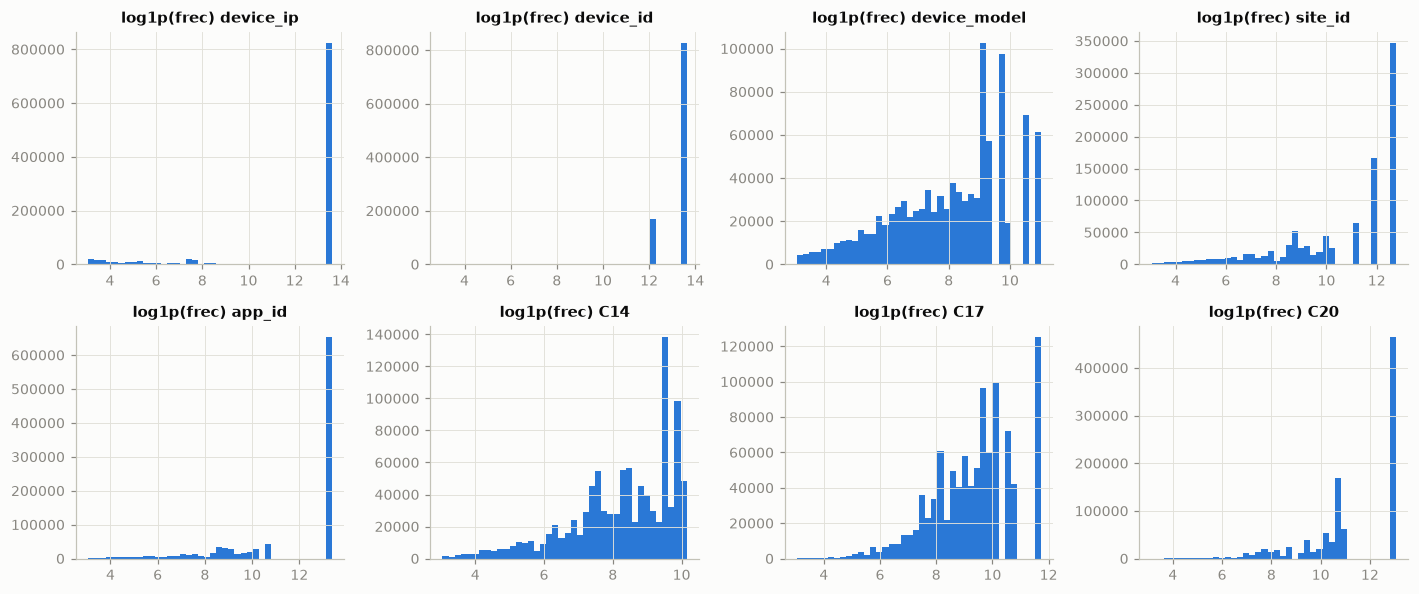

In [6]:
n_eda = min(1_000_000, data.split_sizes(cfg)["train"])
tr = data.read_sample(cfg, "train", n_eda)
y_tr = tr["click"].to_numpy()
feat = CTRFeaturizer(cfg.high_card, cfg.low_card, cfg["rare_min_count"]).fit(tr)
codes = feat.encode(tr)
freq = np.column_stack([np.log1p(feat.counts[c][codes[:, j]]) for j, c in enumerate(feat.cols)])
freq_df = pd.DataFrame(freq, columns=feat.cols)

fig, axs = plt.subplots(2, 4, figsize=(13, 5.5))
for ax, c in zip(axs.ravel(), ["device_ip", "device_id", "device_model", "site_id", "app_id", "C14", "C17", "C20"]):
    ax.hist(freq_df[c], bins=40, color=SERIES[0])
    ax.set_title(f"log1p(frec) {c}", fontsize=10)
savefig(fig, FIG, "02_hist_numericas_derivadas")

## 2.6 Asociación con el clic y entre variables

- **Información mutua** (variables tratadas como discretas, con raras agrupadas).
- **V de Cramér con corrección de sesgo** (Bergsma, 2013), porque la V clásica se infla con
  muchas categorías.
- **Correlación de Spearman** entre las numéricas derivadas (log-frecuencias).

,variable,info_mutua,V_cramer_vs_click
7,C14,0.0373,0.2658
0,site_id,0.0372,0.2752
8,C17,0.0342,0.2605
1,site_domain,0.0328,0.2584
2,app_id,0.0218,0.1812
11,C21,0.0217,0.2013
6,device_model,0.0213,0.1748
9,C19,0.0173,0.1754
20,C18,0.0157,0.1735
3,app_domain,0.0123,0.1374


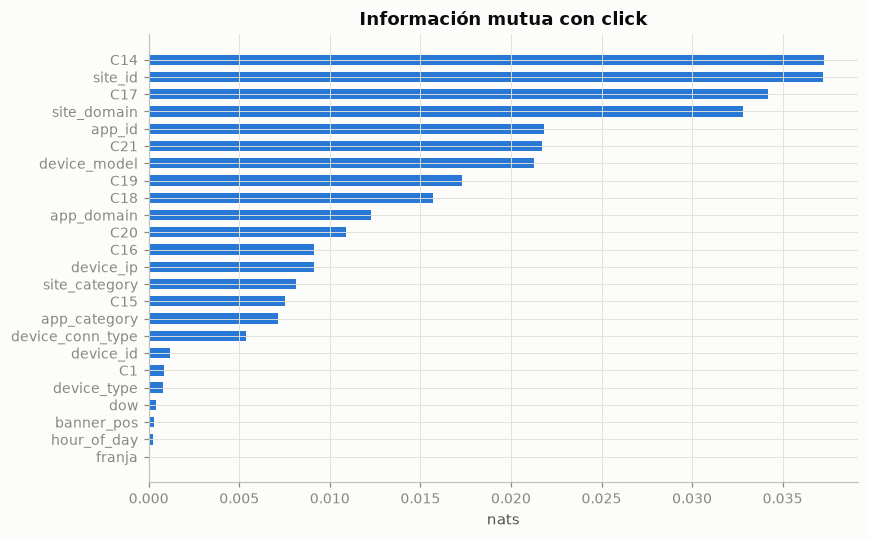

In [7]:
def cramers_v_corrected(x, y):
    tab = pd.crosstab(x, y).to_numpy()
    n = tab.sum()
    chi2 = stats.chi2_contingency(tab, correction=False)[0]
    r, k = tab.shape
    phi2 = chi2 / n
    phi2c = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    den = min(kc - 1, rc - 1)
    return float(np.sqrt(phi2c / den)) if den > 0 else np.nan

rng = np.random.default_rng(cfg["seed_base"])
idx = rng.choice(len(y_tr), size=min(300_000, len(y_tr)), replace=False)
mi = mutual_info_classif(codes[idx], y_tr[idx], discrete_features=True, random_state=cfg["seed_base"])
assoc = pd.DataFrame({"variable": feat.cols, "info_mutua": mi,
                      "V_cramer_vs_click": [cramers_v_corrected(codes[idx, j], y_tr[idx]) for j in range(len(feat.cols))]})
assoc = assoc.sort_values("info_mutua", ascending=False)
assoc.to_csv(RES / "eda_asociacion.csv", index=False)
show(assoc, 30)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(assoc["variable"][::-1], assoc["info_mutua"][::-1], color=SERIES[0], height=0.6)
ax.set_title("Información mutua con click"); ax.set_xlabel("nats")
savefig(fig, FIG, "02_info_mutua")

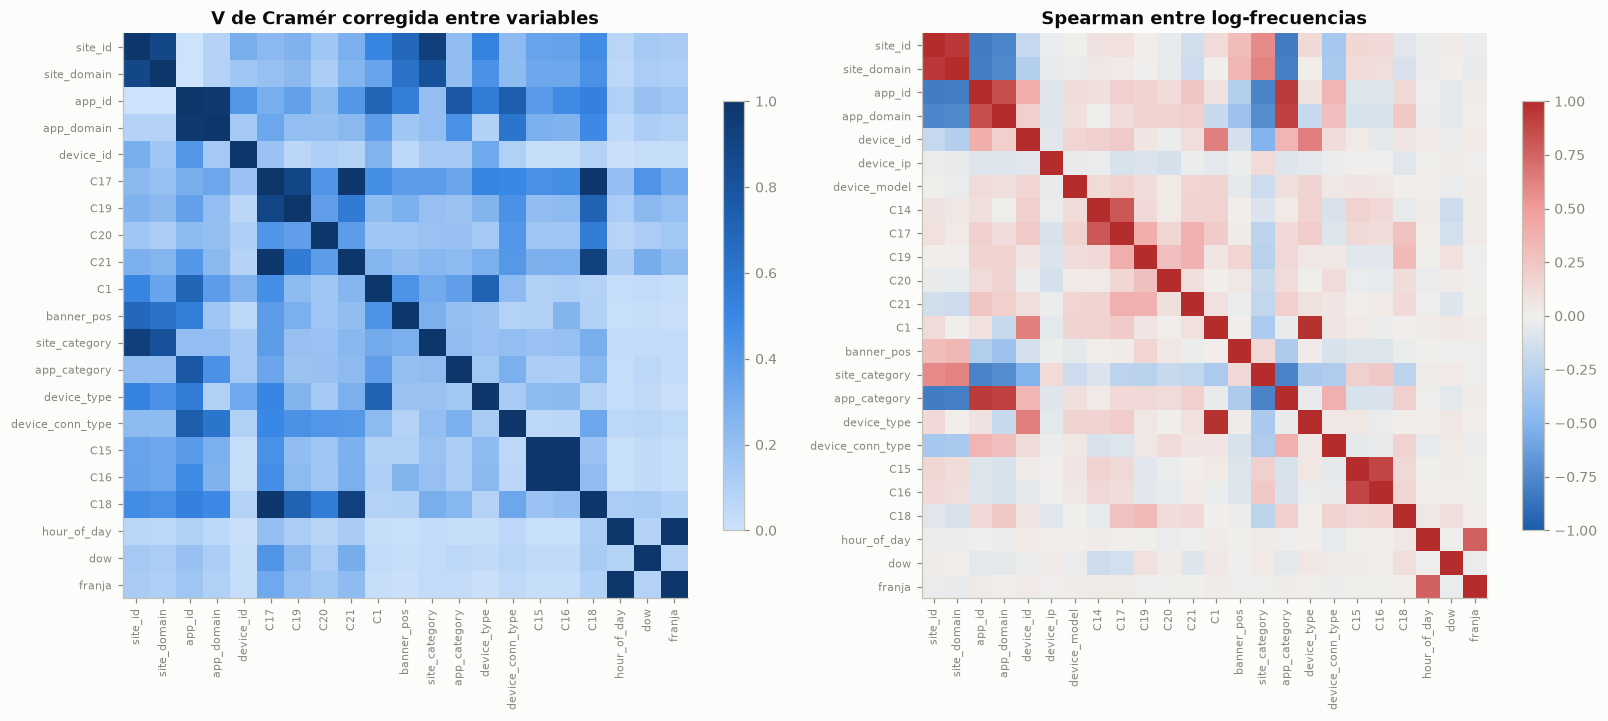

In [8]:
# V de Cramér entre pares de variables (submuestra de 100 mil y variables de cardinalidad moderada)
sub = idx[:100_000]
low = [c for c in feat.cols if len(feat.names[c]) <= 1000]
V = np.eye(len(low))
for i in range(len(low)):
    for j in range(i + 1, len(low)):
        V[i, j] = V[j, i] = cramers_v_corrected(codes[sub, feat.cols.index(low[i])], codes[sub, feat.cols.index(low[j])])
rho = freq_df.iloc[idx[:200_000]].corr(method="spearman")

fig, axs = plt.subplots(1, 2, figsize=(15, 6.5))
im = axs[0].imshow(V, cmap=SEQ_CMAP, vmin=0, vmax=1)
axs[0].set_xticks(range(len(low)), low, rotation=90, fontsize=7); axs[0].set_yticks(range(len(low)), low, fontsize=7)
axs[0].set_title("V de Cramér corregida entre variables"); axs[0].grid(False)
fig.colorbar(im, ax=axs[0], shrink=0.7)
im = axs[1].imshow(rho.values, cmap=DIV_CMAP, vmin=-1, vmax=1)
axs[1].set_xticks(range(len(rho)), rho.columns, rotation=90, fontsize=7); axs[1].set_yticks(range(len(rho)), rho.columns, fontsize=7)
axs[1].set_title("Spearman entre log-frecuencias"); axs[1].grid(False)
fig.colorbar(im, ax=axs[1], shrink=0.7)
savefig(fig, FIG, "02_matrices_asociacion")

## 2.7 Deriva temporal: índice de estabilidad poblacional (PSI)

$\mathrm{PSI} = \sum_i (q_i - p_i)\ln(q_i/p_i)$, con $p$ la distribución en entrenamiento y
$q$ en prueba, sobre las categorías del vocabulario de entrenamiento más `__RARE__`. Criterio
habitual: < 0,1 estable; 0,1–0,25 deriva moderada; > 0,25 deriva fuerte.

,variable,PSI,pct_prueba_en_RARE,pct_train_en_RARE
22,dow,12.4290,0.0001,0.0001
8,C17,6.2261,33.6432,0.0223
7,C14,5.3545,36.8351,0.4588
11,C21,3.3929,19.2504,0.0018
9,C19,2.1668,10.4391,0.0010
2,app_id,0.9666,1.5028,0.9163
10,C20,0.4737,0.0280,0.0105
3,app_domain,0.4007,0.1315,0.0514
0,site_id,0.3688,0.9803,0.8874
6,device_model,0.3431,2.4003,1.6552


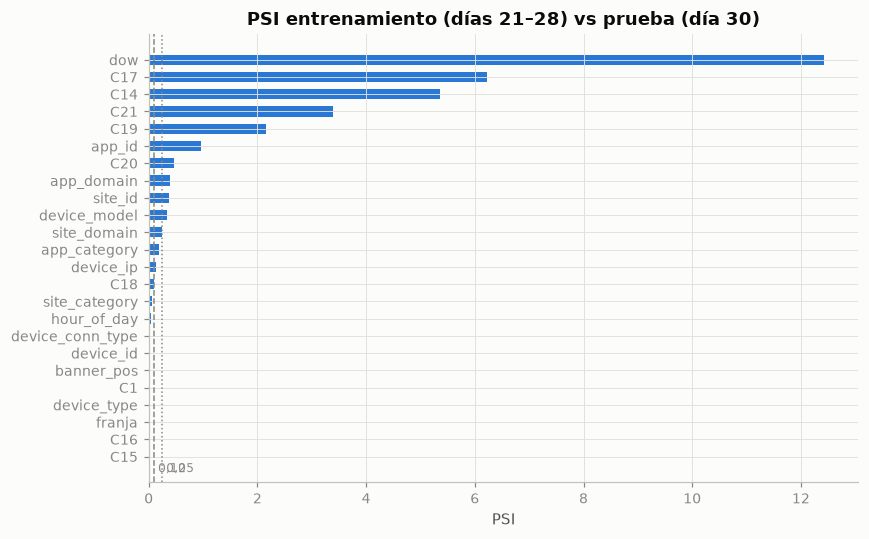

In [9]:
te = data.read_sample(cfg, "test", cfg["test_max_rows"])
codes_te = feat.encode(te)
eps = 1e-6
psi_rows = []
for j, c in enumerate(feat.cols):
    K = len(feat.names[c])
    p = np.bincount(codes[:, j], minlength=K) / len(codes) + eps
    q = np.bincount(codes_te[:, j], minlength=K) / len(codes_te) + eps
    psi_rows.append({"variable": c, "PSI": float(np.sum((q - p) * np.log(q / p))),
                     "pct_prueba_en_RARE": q[0] * 100, "pct_train_en_RARE": p[0] * 100})
psi = pd.DataFrame(psi_rows).sort_values("PSI", ascending=False)
psi.to_csv(RES / "eda_psi.csv", index=False)
show(psi, 30)

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(psi["variable"][::-1], psi["PSI"][::-1], color=SERIES[0], height=0.6)
ax.axvline(0.1, color=MUTED, linestyle="--", linewidth=1); ax.axvline(0.25, color=MUTED, linestyle=":", linewidth=1)
ax.text(0.1, -0.9, " 0,10", color=MUTED, fontsize=8); ax.text(0.25, -0.9, " 0,25", color=MUTED, fontsize=8)
ax.set_title("PSI entrenamiento (días 21–28) vs prueba (día 30)"); ax.set_xlabel("PSI")
savefig(fig, FIG, "02_psi")

## 2.8 Hallazgos que condicionan el modelado

La celda siguiente resume automáticamente los hallazgos cuantitativos; la interpretación se
escribe a partir de esos números (no antes de verlos).

In [10]:
resumen = {
    "tasa_base_global": float(base.get(1, 0) / base.sum()),
    "rango_ctr_diario": (float(by_day["ctr"].min()), float(by_day["ctr"].max())),
    "variable_mas_categorias": card.iloc[0]["variable"],
    "max_categorias": int(card.iloc[0]["categorias"]),
    "top3_info_mutua": assoc["variable"].head(3).tolist(),
    "variables_PSI_mayor_0.1": psi.loc[psi["PSI"] > 0.1, "variable"].tolist(),
}
resumen

{'tasa_base_global': 0.16980562476404604,
 'rango_ctr_diario': (0.15218237478963434, 0.18304894924048956),
 'variable_mas_categorias': 'device_ip',
 'max_categorias': 5566572,
 'top3_info_mutua': ['C14', 'site_id', 'C17'],
 'variables_PSI_mayor_0.1': ['dow',
  'C17',
  'C14',
  'C21',
  'C19',
  'app_id',
  'C20',
  'app_domain',
  'site_id',
  'device_model',
  'site_domain',
  'app_category',
  'device_ip']}